In [1]:
%pylab inline
import gc
import fitsio
import treecorr
import numpy as np
import catutil
import matplotlib.lines as mlines
import astropy.table as astTable
from scipy.optimize import curve_fit

def func(x, a, b):
    return a * x + b

Populating the interactive namespace from numpy and matplotlib


Text(0, 0.5, '$\\delta m$')

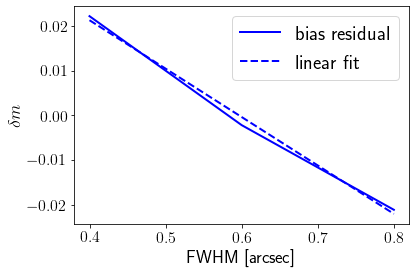

In [58]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName,allow_pickle=True)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            catutil.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

obsname="fwhm"
nbin_1d=3
min_obs=0.3
max_obs=0.9
obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
obs_mean=(obs_bounds[1:]+obs_bounds[:-1])/2.
xlabel='FWHM (arcsec)'
obs_lowers  =   obs_bounds[:-1]
obs_uppers  =   obs_bounds[1:]
obs_ave =   (obs_uppers+obs_lowers)/2.
inDir='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/sanityTest_withZ/'
shearBinName=   os.path.join(inDir,'shear_sanitytest_%s_90rot.npy' %obsname)
m1,a1,sigm1,siga1=get_mc_bins(shearBinName,nbin_1d)

popt, pcov = curve_fit(func, obs_mean, m1)
plt.plot(obs_mean,m1,label='bias residual',c='blue')
plt.plot(obs_mean, func(obs_mean, *popt),label='linear fit',c='blue',ls='--')
plt.legend()
plt.xlabel('FWHM [arcsec]')
plt.ylabel(r'$\delta m$')

In [59]:
nzs    =   4
pzname =   'dnnz' #demp/mizuki/dnnz
fname='mock_nres13_r003_rotmat12_shear_catalog.fits'
dataG  =   [[],[],[],[]]
dataM  =   [[],[],[],[]]
pzDir   =   'wrkDir/catalog/'
for fieldname in catutil.field_names:
    # mock catalog (will copy v2 to GW and idark)
    catFname=  'wrkDir/g3Sim/catalog_obs_reGaus_no_m/%s_no_m.fits' %(fieldname)
    data   =   fitsio.read(catFname)[['i_ra','i_dec','i_sdssshape_psf_shape11',\
                                    'i_sdssshape_psf_shape12','i_sdssshape_psf_shape22']]
    catFname=  'wrkDir/g3Sim/catalog_mock/shape_v2/%s/%s' %(fieldname,fname)
    data2   =   fitsio.read(catFname)
    pzsname=   os.path.join(pzDir,'%s_%s_zmask.fits' %(fieldname,pzname))
    for iz in range(nzs):
        zmsk   =   fitsio.read(pzsname)['%s_mask_%sbin' %(pzname,iz)]
        # merge observational fields
        dataG[iz].append(data[zmsk])
        dataM[iz].append(data2[zmsk])
    del data,data2
    gc.collect()
dataG=[np.hstack(dataG[i]) for i in range(nzs)]
dataM=[np.hstack(dataM[i]) for i in range(nzs)]

In [60]:
cor  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
out1 =   []

for i in range(nzs):
    mp1=1+func(catutil.get_psf_size(dataG[i]),*popt)
    g1=dataM[i]['shear1_sim']*mp1
    g2=dataM[i]['shear2_sim']*mp1
    cat1  =   treecorr.Catalog(g1=g1,g2=-g2,
                            ra=dataM[i]['ra_mock'],dec=dataM[i]['dec_mock'],
                            ra_units='deg',dec_units='deg') 
    cat2  =   treecorr.Catalog(g1=g1,g2=-g2,
                            ra=dataM[i]['ra_mock'],dec=dataM[i]['dec_mock'],
                            ra_units='deg',dec_units='deg') 
    # correlation 
    cor.clear()
    cor.process(cat1,cat2)
    out1.append(cor.copy())

In [61]:
out2 =   []
for i in range(nzs):
    g1=dataM[i]['shear1_sim']
    g2=dataM[i]['shear2_sim']
    cat1  =   treecorr.Catalog(g1=g1,g2=-g2,
                            ra=dataM[i]['ra_mock'],dec=dataM[i]['dec_mock'],
                            ra_units='deg',dec_units='deg') 
    cat2  =   treecorr.Catalog(g1=g1,g2=-g2,
                            ra=dataM[i]['ra_mock'],dec=dataM[i]['dec_mock'],
                            ra_units='deg',dec_units='deg') 
    # correlation 
    cor.clear()
    cor.process(cat1,cat2)
    out2.append(cor.copy())

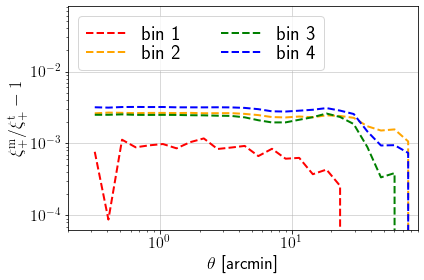

In [73]:
plt.close()
clist=['red','orange','green','blue']
fig = plt.figure()
ax=fig.add_subplot(1,1,1)
for i in range(nzs):
    ax.plot(out1[i].meanr,out1[i].xip/out2[i].xip-1,'--',c=clist[i],label='bin %d' %(i+1))
#ax.plot(out[0].meanr,np.abs(out[1].xim-out[0].xim),'--')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(loc='upper left',ncol=2,handleheight=.5, labelspacing=0.01)
ax.set_ylabel(r'$\xi_{+}^{\rm m}/\xi_{+}^{\rm t}-1$')
ax.set_xlabel(r'$\theta$ [arcmin]')
ax.set_xlim(0.2,90)
#ax.set_ylim(2e-10,5e-4)
ax.grid()
plt.tight_layout()
fig.savefig('wrkDir/plot/seeing_check.pdf')
fig.savefig('wrkDir/plot/seeing_check.png')

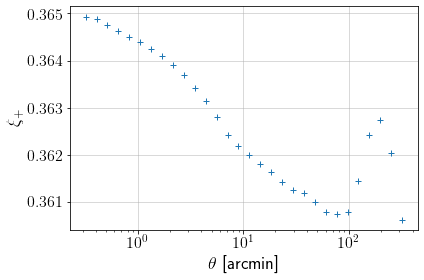

In [19]:
cor2  =   treecorr.KKCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
fwhm  =   catutil.get_psf_size(dataO)
cat1  =   treecorr.Catalog(k=fwhm,
                        ra=data['ra_mock'],dec=data['dec_mock'],
                        ra_units='deg',dec_units='deg') 
cat2  =   treecorr.Catalog(k=fwhm,
                        ra=data['ra_mock'],dec=data['dec_mock'],
                        ra_units='deg',dec_units='deg') 
# correlation 
cor2.clear()
cor2.process(cat1,cat2)
plt.close()
fig = plt.figure()
ax=fig.add_subplot(1,1,1)
ax.plot(cor2.meanr,cor2.xi,'+')
ax.set_xscale('log')
ax.set_ylabel(r'$\xi_{+}$')
ax.set_xlabel(r'$\theta$ [arcmin]')
ax.grid()
plt.tight_layout()